In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

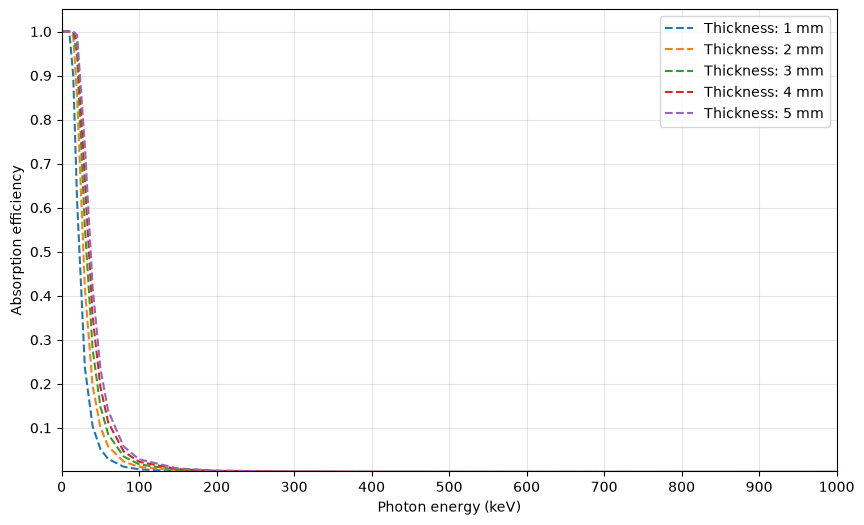

In [33]:
# for multiple thickness
rho = 2.33  # CdZnTe density (g/cm³)
thicknesses = [0.1, 0.2, 0.3, 0.4, 0.5]   # cm

df = pd.read_csv("data/Si.csv", sep=r"\s+", names=["E", "pe"])  # pe = mu/rho (cm²/g)
df = df.apply(pd.to_numeric, errors="coerce").dropna()   # drops the text header rows

E = df["E"].values * 1000 # MeV -> keV

plt.figure(figsize=(10, 6))
for t in thicknesses:
    eff_pe = 1 - np.exp(-df["pe"].values * rho * t)
    plt.plot(E, eff_pe, '--', label=f'Thickness: {t*10:.0f} mm')   # plot, not semilogx

plt.xlabel("Photon energy (keV)")
plt.ylabel("Absorption efficiency")
plt.xlim(100, 1000)
plt.ylim(0.001, 1.05)
plt.xticks(np.arange(0, 1001, 100))
plt.yticks(np.arange(0.1, 1.01, 0.1))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

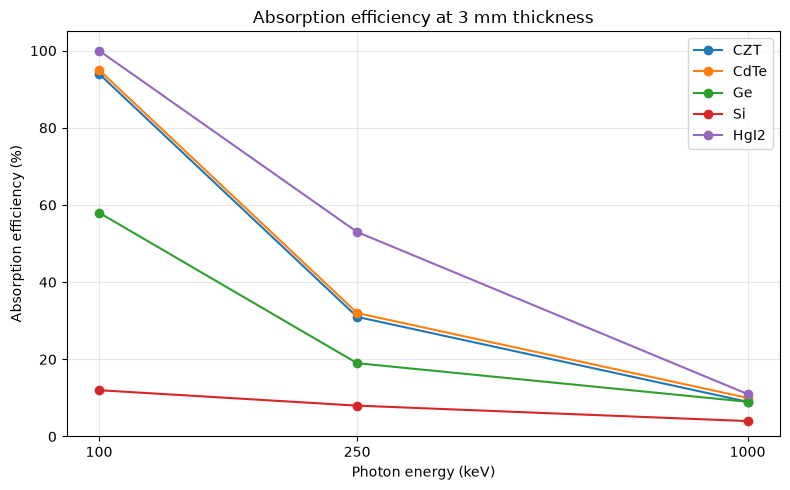

In [26]:
abs_eff = {"CZT":  [94, 31, 9],
           "CdTe": [95, 32, 10],
           "Ge":   [58, 19, 9],
           "Si":   [12, 8, 4],
           "HgI2": [100, 53, 11]}

energy = [100, 250, 1000]   # keV, at 3 mm thickness

plt.figure(figsize=(8, 5))
for material, eff in abs_eff.items():
    plt.plot(energy, eff, marker='o', ms=6, lw=1.5, label=material)

plt.xscale('log')
plt.xticks(energy, [str(e) for e in energy])   # show 100, 250, 1000 as plain labels
plt.minorticks_off()                           # removes the extra minor ticks on the log axis

plt.xlabel("Photon energy (keV)")
plt.ylabel("Absorption efficiency (%)")
plt.title("Absorption efficiency at 3 mm thickness")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()